Supplementary figure: design robustness

In [1]:
# ============================================================
# Supplementary Simulation — Design / robustness stress tests
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import isovita as iso
import isovita_simulation as isim


# ============================================================
# 1. Reference design
# ============================================================

TRUTH_TYPES = (
    "discrete",
    "continuous",
)

N_REPLICATES = 20


# ------------------------------------------------------------
# Genes per simulated condition
# ------------------------------------------------------------

GENES_PER_TRUTH = 5

N_ALTERNATIVE = (
    len(TRUTH_TYPES)
    * GENES_PER_TRUTH
)

# Equal null / non-null mixture.
N_NULL = N_ALTERNATIVE

N_GENES = (
    N_ALTERNATIVE
    + N_NULL
)


# ------------------------------------------------------------
# Reference condition
#
# Calibrated between the previous near-ceiling regime
# (0.18 signal, N=100, noise=0.30)
# and the previous near-floor regime
# (0.10 signal, N=60, noise=0.45).
# ------------------------------------------------------------

REFERENCE_SIGNAL = 0.14

REFERENCE_N = 80
REFERENCE_K = 4

REFERENCE_NOISE_SD = 0.35
REFERENCE_NOISE_CORR = 0.10

REFERENCE_AGE_DESIGN = "uniform"


ALPHA_FDR = 0.05

# 20 genes per branch:
# first BH threshold = 0.05 / 20 = 0.0025.
#
# 1000 permutations:
# minimum attainable p ~= 0.001.
N_PERMUTATIONS = 1000

N_JOBS = 8

BASE_SEED = 20260927


# ============================================================
# Canonical temporal geometry
# ============================================================

TRUE_CHANGE_AGE = 35.0

CONTINUOUS_CENTER = 42.0
CONTINUOUS_SCALE = 16.0


# ============================================================
# One-factor-at-a-time robustness grid
#
# Every numeric grid contains the reference condition.
# ============================================================

ROBUSTNESS_GRID = {

    "sample_size": [
        40,
        60,
        80,
        120,
        180,
    ],

    "noise_sd": [
        0.20,
        0.28,
        0.35,
        0.45,
        0.60,
    ],

    # Exactly two isoforms carry strong signal.
    # Increasing K adds passenger isoforms.
    "k": [
        2,
        4,
        6,
        8,
        12,
    ],

    "age_design": [
        "balanced",
        "uniform",
        "middle_heavy",
        "young_heavy",
        "old_heavy",
    ],
}


DISPLAY_LABELS = {

    "balanced":
        "Balanced",

    "uniform":
        "Uniform",

    "middle_heavy":
        "Middle-heavy",

    "young_heavy":
        "Early-heavy",

    "old_heavy":
        "Late-heavy",
}


REFERENCE_LEVELS = {

    "sample_size":
        REFERENCE_N,

    "noise_sd":
        REFERENCE_NOISE_SD,

    "k":
        REFERENCE_K,

    "age_design":
        REFERENCE_AGE_DESIGN,
}


# ============================================================
# Shared IsoVita configurations
# ============================================================

BALANCE_CONFIG = iso.BalanceConfig()

DISCRETE_CONFIG = iso.DiscreteConfig(
    alpha_fdr=ALPHA_FDR,
)

CONTINUOUS_CONFIG = iso.ContinuousConfig(
    alpha_fdr=ALPHA_FDR,
)


# ============================================================
# Permutation-resolution check
# ============================================================

minimum_p = (
    1.0
    / (N_PERMUTATIONS + 1.0)
)

first_bh_threshold = (
    ALPHA_FDR
    / N_GENES
)


print(
    f"Genes per condition: {N_GENES}"
)

print(
    "Reference signal amplitude:",
    REFERENCE_SIGNAL,
)

print(
    "Reference sample size:",
    REFERENCE_N,
)

print(
    "Reference noise SD:",
    REFERENCE_NOISE_SD,
)

print(
    "Minimum permutation p-value:",
    f"{minimum_p:.6f}",
)

print(
    "First BH threshold:",
    f"{first_bh_threshold:.6f}",
)

Genes per condition: 20
Reference signal amplitude: 0.14
Reference sample size: 80
Reference noise SD: 0.35
Minimum permutation p-value: 0.000999
First BH threshold: 0.002500


In [2]:
# ============================================================
# 2. Scenario helpers
# ============================================================

def stable_code(
    value,
):
    """
    Deterministic integer derived from an arbitrary value.
    """
    value = str(
        value
    )

    return sum(
        (i + 1)
        * ord(character)
        for i, character
        in enumerate(value)
    )


def make_primary_loadings(
    k,
    rng,
):
    """
    Construct a sparse planted temporal direction.

    Exactly two isoforms carry the dominant signal:

        TX1: positive
        TX2: negative

    Additional effective isoforms are passengers with only
    very small loading perturbations.

    Increasing K therefore directly tests sparse feature
    condensation in the presence of additional effective,
    weakly informative isoforms.
    """

    if k < 2:

        raise ValueError(
            "k must be at least 2."
        )


    loading = np.zeros(
        k,
        dtype=float,
    )

    loading[
        0
    ] = 1.0

    loading[
        1
    ] = -1.0


    # Mild perturbation prevents exact duplicate simulation
    # geometries while leaving added isoforms primarily
    # passenger trajectories.
    loading += rng.normal(
        0.0,
        0.02,
        size=k,
    )


    # Common shifts disappear under softmax.
    loading -= (
        loading.mean()
    )


    loading /= (
        np.max(
            np.abs(
                loading
            )
        )
    )


    return tuple(
        loading.tolist()
    )


def make_gene_baselines(
    k,
    rng,
):
    """
    Moderate heterogeneous baseline isoform composition.
    """

    return tuple(
        rng.normal(
            0.0,
            0.25,
            size=k,
        ).tolist()
    )


def make_primary_component(
    truth_type,
    loadings,
    amplitude,
):
    """
    Construct the temporal component corresponding to one of
    the two production IsoVita hypotheses.
    """

    if truth_type == "discrete":

        return isim.TemporalComponent(
            kind="step",
            loadings=loadings,
            amplitude=float(
                amplitude
            ),
            params={
                "change_age":
                    TRUE_CHANGE_AGE,
            },
        )


    if truth_type == "continuous":

        return isim.TemporalComponent(
            kind="sigmoid",
            loadings=loadings,
            amplitude=float(
                amplitude
            ),
            params={
                "center":
                    CONTINUOUS_CENTER,

                "scale":
                    CONTINUOUS_SCALE,
            },
        )


    raise ValueError(
        f"Unknown truth type: {truth_type}"
    )


# ============================================================
# Age-design helper
# ============================================================

def make_stress_ages(
    n_samples,
    design,
    seed,
):
    """
    Generate age distributions with different coverage of the
    0-85 year interval.

    The skewed designs are deliberately nonuniform but are less
    extreme than the previous beta(1.25, 3.25) stress cases.
    """

    rng = np.random.default_rng(
        seed
    )


    if design == "balanced":

        unit = (
            (
                np.arange(
                    n_samples,
                    dtype=float,
                )
                + 0.5
            )
            / n_samples
        )

        unit += rng.normal(
            0.0,
            0.10 / n_samples,
            size=n_samples,
        )

        unit = np.clip(
            unit,
            0.0,
            1.0,
        )


    elif design == "uniform":

        unit = rng.uniform(
            0.0,
            1.0,
            size=n_samples,
        )


    elif design == "middle_heavy":

        unit = rng.beta(
            2.0,
            2.0,
            size=n_samples,
        )


    elif design == "young_heavy":

        unit = rng.beta(
            1.5,
            2.5,
            size=n_samples,
        )


    elif design == "old_heavy":

        unit = rng.beta(
            2.5,
            1.5,
            size=n_samples,
        )


    else:

        raise ValueError(
            f"Unknown age design: {design}"
        )


    ages = (
        85.0
        * unit
    )


    return np.sort(
        ages.astype(float)
    )

In [3]:
# ============================================================
# 3. Construct one robustness condition
# ============================================================

def resolve_robustness_settings(
    factor,
    level,
):
    """
    Begin from the common reference condition and perturb
    exactly one simulation setting.
    """

    settings = {

        "n_samples":
            REFERENCE_N,

        "k":
            REFERENCE_K,

        "noise_sd":
            REFERENCE_NOISE_SD,

        "noise_corr":
            REFERENCE_NOISE_CORR,

        "age_design":
            REFERENCE_AGE_DESIGN,
    }


    if factor == "sample_size":

        settings[
            "n_samples"
        ] = int(
            level
        )


    elif factor == "noise_sd":

        settings[
            "noise_sd"
        ] = float(
            level
        )


    elif factor == "k":

        settings[
            "k"
        ] = int(
            level
        )


    elif factor == "age_design":

        settings[
            "age_design"
        ] = str(
            level
        )


    else:

        raise ValueError(
            f"Unknown robustness factor: {factor}"
        )


    return settings


def make_robustness_scenarios(
    factor,
    level,
    replicate,
):
    """
    Build one mixed null/non-null dataset for a single
    one-factor-at-a-time robustness condition.
    """

    settings = (
        resolve_robustness_settings(
            factor,
            level,
        )
    )


    k = int(
        settings[
            "k"
        ]
    )


    seed = (
        BASE_SEED
        + 100_000 * replicate
        + 100 * stable_code(
            factor
        )
        + stable_code(
            level
        )
    )


    rng = np.random.default_rng(
        seed
    )


    scenarios = []
    truth_rows = []


    # --------------------------------------------------------
    # Age-null genes
    # --------------------------------------------------------

    for i in range(
        N_NULL
    ):

        gene_id = (
            f"R{replicate:03d}_"
            f"{factor}_NULL_"
            f"{i + 1:03d}"
        )


        scenarios.append(
            isim.IsoformScenario(
                gene_id=gene_id,
                label="Age-null",
                baselines=(
                    make_gene_baselines(
                        k,
                        rng,
                    )
                ),
                components=(),
                noise_sd=float(
                    settings[
                        "noise_sd"
                    ]
                ),
                noise_corr=float(
                    settings[
                        "noise_corr"
                    ]
                ),
            )
        )


        truth_rows.append({
            "gene_id":
                gene_id,

            "truth_type":
                "null",

            "factor":
                factor,

            "level":
                level,
        })


    # --------------------------------------------------------
    # Alternative genes
    # --------------------------------------------------------

    for truth_type in (
        TRUTH_TYPES
    ):

        for gene_index in range(
            GENES_PER_TRUTH
        ):

            gene_id = (
                f"R{replicate:03d}_"
                f"{factor}_"
                f"{truth_type.upper()}_"
                f"{gene_index + 1}"
            )


            primary_loadings = (
                make_primary_loadings(
                    k,
                    rng,
                )
            )


            primary_component = (
                make_primary_component(
                    truth_type,
                    primary_loadings,
                    REFERENCE_SIGNAL,
                )
            )


            scenarios.append(
                isim.IsoformScenario(
                    gene_id=gene_id,
                    label=(
                        truth_type.capitalize()
                    ),
                    baselines=(
                        make_gene_baselines(
                            k,
                            rng,
                        )
                    ),
                    components=(
                        primary_component,
                    ),
                    noise_sd=float(
                        settings[
                            "noise_sd"
                        ]
                    ),
                    noise_corr=float(
                        settings[
                            "noise_corr"
                        ]
                    ),
                )
            )


            truth_rows.append({
                "gene_id":
                    gene_id,

                "truth_type":
                    truth_type,

                "factor":
                    factor,

                "level":
                    level,
            })


    return (
        tuple(
            scenarios
        ),
        pd.DataFrame(
            truth_rows
        ),
        settings,
    )

In [4]:
# ============================================================
# 4. Run one robustness condition
# ============================================================

def run_robustness_condition(
    factor,
    level,
    replicate,
):
    """
    Simulate and analyze one robustness condition using both
    production IsoVita branches.
    """

    (
        scenarios,
        truth,
        settings,
    ) = make_robustness_scenarios(
        factor,
        level,
        replicate,
    )


    # --------------------------------------------------------
    # Reproducible age design
    # --------------------------------------------------------

    age_seed = (
        BASE_SEED
        + 150_000 * replicate
        + 100 * stable_code(
            factor
        )
        + stable_code(
            level
        )
    )


    ages = make_stress_ages(
        n_samples=int(
            settings[
                "n_samples"
            ]
        ),
        design=(
            settings[
                "age_design"
            ]
        ),
        seed=age_seed,
    )


    # --------------------------------------------------------
    # Simulate transcript-level data
    # --------------------------------------------------------

    sim_seed = (
        BASE_SEED
        + 200_000 * replicate
        + 100 * stable_code(
            factor
        )
        + stable_code(
            level
        )
    )


    sim_data = (
        isim.simulate_isovita_dataset(
            scenarios,
            ages=ages,
            seed=sim_seed,
            sample_prefix=(
                f"R{replicate:03d}_S"
            ),
        )
    )


    sample_cols = (
        sim_data.metadata
        .index
        .tolist()
    )


    # --------------------------------------------------------
    # Run-local reusable objects
    # --------------------------------------------------------

    prepared_cache = {}
    spline_workspace_cache = {}
    permutation_order_cache = {}


    # --------------------------------------------------------
    # Observed feature condensation
    # --------------------------------------------------------

    (
        balance_summary,
        _,
        balance_feature_matrix,
    ) = iso.build_one_feature_per_gene(
        expression_df=(
            sim_data.expression
        ),
        global_metrics=(
            sim_data.global_metrics
        ),
        sample_cols=sample_cols,
        metadata=sim_data.metadata,
        config=BALANCE_CONFIG,
        prepared_cache=(
            prepared_cache
        ),
        spline_workspace_cache=(
            spline_workspace_cache
        ),
    )


    failed = (
        balance_summary.loc[
            ~balance_summary[
                "status"
            ].eq("ok")
        ]
    )


    if not failed.empty:

        raise RuntimeError(
            "Feature condensation failed:\n"
            + failed.to_string()
        )


    # --------------------------------------------------------
    # Selection-aware production inference
    # --------------------------------------------------------

    branch_results = (
        iso.run_selection_aware_temporal_tests(
            observed_feature_matrix=(
                balance_feature_matrix
            ),
            prepared_cache=(
                prepared_cache
            ),
            branches=TRUTH_TYPES,
            balance_config=(
                BALANCE_CONFIG
            ),
            discrete_config=(
                DISCRETE_CONFIG
            ),
            continuous_config=(
                CONTINUOUS_CONFIG
            ),
            inference_config=(
                iso.PermutationInferenceConfig(
                    n_permutations=(
                        N_PERMUTATIONS
                    ),
                    random_seed=(
                        BASE_SEED
                        + 300_000 * replicate
                        + stable_code(
                            factor
                        )
                        + stable_code(
                            level
                        )
                    ),
                )
            ),
            n_jobs=N_JOBS,
            spline_workspace_cache=(
                spline_workspace_cache
            ),
            permutation_order_cache=(
                permutation_order_cache
            ),
        )
    )


    # --------------------------------------------------------
    # Compact branch-call tables
    # --------------------------------------------------------

    discrete_calls = (
        branch_results[
            "discrete"
        ][
            [
                "gene_id",
                "fdr_significant",
            ]
        ]
        .rename(
            columns={
                "fdr_significant":
                    "discrete_called",
            }
        )
    )


    continuous_calls = (
        branch_results[
            "continuous"
        ][
            [
                "gene_id",
                "fdr_significant",
            ]
        ]
        .rename(
            columns={
                "fdr_significant":
                    "continuous_called",
            }
        )
    )


    balance_quality = (
        balance_summary.loc[
            balance_summary[
                "status"
            ].eq("ok"),
            [
                "gene_id",
                "pc1_explained_variance_ratio",
                "cosine_similarity",
            ],
        ]
    )


    # --------------------------------------------------------
    # Merge truth and results
    # --------------------------------------------------------

    calls = (
        truth
        .merge(
            balance_quality,
            on="gene_id",
            how="left",
            validate="one_to_one",
        )
        .merge(
            discrete_calls,
            on="gene_id",
            how="left",
            validate="one_to_one",
        )
        .merge(
            continuous_calls,
            on="gene_id",
            how="left",
            validate="one_to_one",
        )
    )


    call_columns = [
        "discrete_called",
        "continuous_called",
    ]


    if calls[
        call_columns
    ].isna().any().any():

        raise RuntimeError(
            "Some simulated genes are missing from "
            "the IsoVita branch results."
        )


    for column in (
        call_columns
    ):

        calls[
            column
        ] = (
            calls[
                column
            ]
            .astype(bool)
        )


    calls[
        "replicate"
    ] = replicate


    return calls

In [5]:
# ============================================================
# 5. Run all robustness simulations
# ============================================================

robustness_results = []


for factor, levels in (
    ROBUSTNESS_GRID.items()
):

    for level in levels:

        for replicate in range(
            N_REPLICATES
        ):

            print(
                f"{factor}={level} | "
                f"replicate "
                f"{replicate + 1}/"
                f"{N_REPLICATES}",
                flush=True,
            )


            robustness_results.append(
                run_robustness_condition(
                    factor,
                    level,
                    replicate,
                )
            )


robustness_calls = (
    pd.concat(
        robustness_results,
        ignore_index=True,
    )
)


# ============================================================
# Save expensive simulation results
# ============================================================

RESULT_DIR = Path(
    "results/simulation_robustness"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


robustness_calls.to_csv(
    RESULT_DIR
    / "robustness_gene_calls.csv",
    index=False,
)


print(
    robustness_calls.shape
)

display(
    robustness_calls.head()
)

sample_size=40 | replicate 1/20
sample_size=40 | replicate 2/20
sample_size=40 | replicate 3/20
sample_size=40 | replicate 4/20
sample_size=40 | replicate 5/20
sample_size=40 | replicate 6/20
sample_size=40 | replicate 7/20
sample_size=40 | replicate 8/20
sample_size=40 | replicate 9/20
sample_size=40 | replicate 10/20
sample_size=40 | replicate 11/20
sample_size=40 | replicate 12/20
sample_size=40 | replicate 13/20
sample_size=40 | replicate 14/20
sample_size=40 | replicate 15/20
sample_size=40 | replicate 16/20
sample_size=40 | replicate 17/20
sample_size=40 | replicate 18/20
sample_size=40 | replicate 19/20
sample_size=40 | replicate 20/20
sample_size=60 | replicate 1/20
sample_size=60 | replicate 2/20
sample_size=60 | replicate 3/20
sample_size=60 | replicate 4/20
sample_size=60 | replicate 5/20
sample_size=60 | replicate 6/20
sample_size=60 | replicate 7/20
sample_size=60 | replicate 8/20
sample_size=60 | replicate 9/20
sample_size=60 | replicate 10/20
sample_size=60 | replicate 1

,gene_id,truth_type,factor,level,pc1_explained_variance_ratio,cosine_similarity,discrete_called,continuous_called,replicate
0,R000_sample_size_NULL_001,null,sample_size,40,0.607992,0.960483,False,False,0
1,R000_sample_size_NULL_002,null,sample_size,40,0.844302,0.983754,False,False,0
2,R000_sample_size_NULL_003,null,sample_size,40,0.724343,0.983955,False,False,0
3,R000_sample_size_NULL_004,null,sample_size,40,0.816238,0.953549,False,False,0
4,R000_sample_size_NULL_005,null,sample_size,40,0.809908,0.970291,False,False,0


In [6]:
# ============================================================
# 6. Summarize matched-branch power
# ============================================================

robustness_alt = (
    robustness_calls.loc[
        ~robustness_calls[
            "truth_type"
        ].eq("null")
    ]
    .copy()
)


# ------------------------------------------------------------
# Matched production branch
# ------------------------------------------------------------

robustness_alt[
    "matched_called"
] = np.where(
    robustness_alt[
        "truth_type"
    ].eq(
        "discrete"
    ),
    robustness_alt[
        "discrete_called"
    ],
    robustness_alt[
        "continuous_called"
    ],
).astype(bool)


# ------------------------------------------------------------
# Replicate-level power
# ------------------------------------------------------------

robustness_by_rep = (
    robustness_alt
    .groupby(
        [
            "factor",
            "level",
            "replicate",
            "truth_type",
        ],
        as_index=False,
    )
    .agg(
        matched_power=(
            "matched_called",
            "mean",
        )
    )
)


# ============================================================
# Mean + 95% CI helper
# ============================================================

def mean_ci(
    values,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    n = len(
        values
    )


    if n == 0:

        return pd.Series({
            "mean":
                np.nan,

            "ci_low":
                np.nan,

            "ci_high":
                np.nan,
        })


    mean = float(
        np.mean(
            values
        )
    )


    if n == 1:

        return pd.Series({
            "mean":
                mean,

            "ci_low":
                np.nan,

            "ci_high":
                np.nan,
        })


    se = (
        np.std(
            values,
            ddof=1,
        )
        / np.sqrt(n)
    )


    return pd.Series({
        "mean":
            mean,

        "ci_low":
            max(
                0.0,
                mean - 1.96 * se,
            ),

        "ci_high":
            min(
                1.0,
                mean + 1.96 * se,
            ),
    })


# ============================================================
# Aggregate across replicates
# ============================================================

robustness_power = (
    robustness_by_rep
    .groupby(
        [
            "factor",
            "level",
            "truth_type",
        ]
    )[
        "matched_power"
    ]
    .apply(
        mean_ci
    )
    .unstack()
    .reset_index()
)


robustness_power.to_csv(
    RESULT_DIR
    / "robustness_power_summary.csv",
    index=False,
)


display(
    robustness_power
)

,factor,level,truth_type,mean,ci_low,ci_high
0,age_design,balanced,continuous,0.74,0.659062,0.820938
1,age_design,balanced,discrete,0.85,0.765279,0.934721
2,age_design,middle_heavy,continuous,0.33,0.218852,0.441148
3,age_design,middle_heavy,discrete,0.48,0.331138,0.628862
4,age_design,old_heavy,continuous,0.09,0.023457,0.156543
5,age_design,old_heavy,discrete,0.10,0.012346,0.187654
6,age_design,uniform,continuous,0.64,0.535123,0.744877
7,age_design,uniform,discrete,0.71,0.627210,0.792790
8,age_design,young_heavy,continuous,0.23,0.138841,0.321159
9,age_design,young_heavy,discrete,0.74,0.669762,0.810238


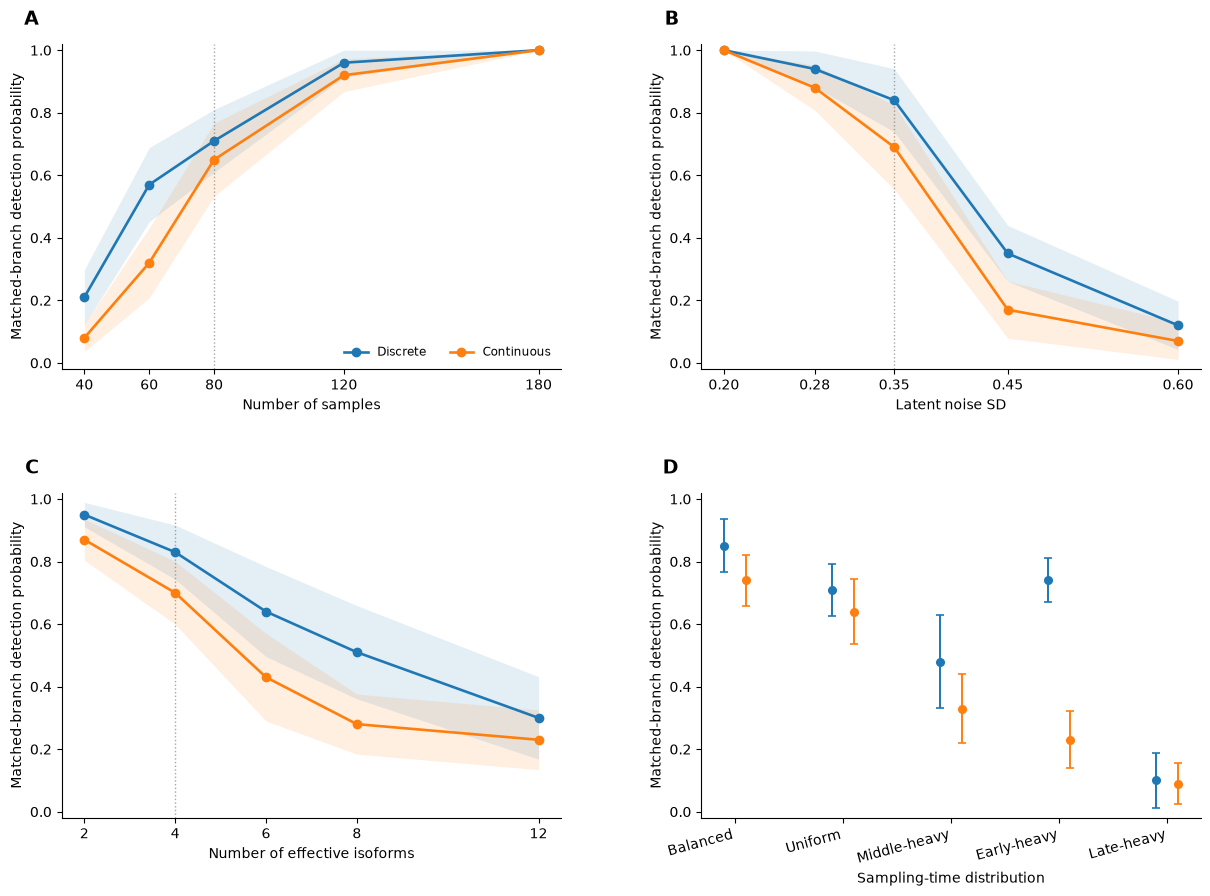

In [7]:
# ============================================================
# 7. Plot design / robustness figure
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12.8, 9.0),
)

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.09,
    top=0.95,
    wspace=0.28,
    hspace=0.38,
)


# ============================================================
# Panel specification
# ============================================================

PANELS = [

    (
        axes[0, 0],
        "sample_size",
        "Number of samples",
    ),

    (
        axes[0, 1],
        "noise_sd",
        "Latent noise SD",
    ),

    (
        axes[1, 0],
        "k",
        "Number of effective isoforms",
    ),

    (
        axes[1, 1],
        "age_design",
        "Sampling-time distribution",
    ),
]


# ============================================================
# Generic panel plotting helper
# ============================================================

def plot_robustness_panel(
    ax,
    factor,
    xlabel,
):
    levels = (
        ROBUSTNESS_GRID[
            factor
        ]
    )


    sub = (
        robustness_power.loc[
            robustness_power[
                "factor"
            ].eq(
                factor
            )
        ]
        .copy()
    )


    categorical = isinstance(
        levels[0],
        str,
    )


    if categorical:

        x_values = np.arange(
            len(levels)
        )

    else:

        x_values = np.asarray(
            levels,
            dtype=float,
        )


    order_map = {
        str(level):
            i
        for i, level
        in enumerate(levels)
    }


    # Small horizontal offsets so the two
    # truth types do not overlap in Panel D.
    if categorical:

        offsets = np.linspace(
            -0.10,
            0.10,
            len(TRUTH_TYPES),
        )


    for truth_idx, truth_type in enumerate(
        TRUTH_TYPES
    ):

        curve = (
            sub.loc[
                sub[
                    "truth_type"
                ].eq(
                    truth_type
                )
            ]
            .copy()
        )


        curve[
            "_order"
        ] = (
            curve[
                "level"
            ]
            .astype(str)
            .map(
                order_map
            )
        )


        if curve[
            "_order"
        ].isna().any():

            raise RuntimeError(
                f"Could not order levels for {factor}."
            )


        curve = (
            curve.sort_values(
                "_order"
            )
        )


        if categorical:

            x_plot = (
                x_values
                + offsets[
                    truth_idx
                ]
            )


            ax.errorbar(
                x_plot,
                curve[
                    "mean"
                ],
                yerr=[
                    curve[
                        "mean"
                    ]
                    - curve[
                        "ci_low"
                    ],
                    curve[
                        "ci_high"
                    ]
                    - curve[
                        "mean"
                    ],
                ],
                fmt="o",
                ms=5.5,
                capsize=3,
                elinewidth=1.4,
                capthick=1.2,
                label=(
                    truth_type.capitalize()
                ),
            )


        else:

            line, = ax.plot(
                x_values,
                curve[
                    "mean"
                ],
                marker="o",
                lw=1.9,
                label=(
                    truth_type.capitalize()
                ),
            )


            ax.fill_between(
                x_values,
                curve[
                    "ci_low"
                ],
                curve[
                    "ci_high"
                ],
                alpha=0.12,
                color=line.get_color(),
                linewidth=0,
            )


    if categorical:

        ax.set_xticks(
            x_values
        )

        ax.set_xticklabels(
            [
                DISPLAY_LABELS.get(
                    level,
                    str(level),
                )
                for level
                in levels
            ],
            rotation=15,
            ha="right",
        )


    else:

        ax.set_xticks(
            x_values
        )

        # Common reference condition for the
        # one-factor-at-a-time design.
        ax.axvline(
            REFERENCE_LEVELS[
                factor
            ],
            ls=":",
            lw=1.0,
            color="0.65",
            zorder=0,
        )


    ax.set_ylim(
        -0.02,
        1.02,
    )

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylabel(
        "Matched-branch detection probability"
    )


# ============================================================
# Draw all four panels
# ============================================================

for (
    ax,
    factor,
    xlabel,
) in PANELS:

    plot_robustness_panel(
        ax,
        factor,
        xlabel,
    )


# ============================================================
# Shared cosmetics
# ============================================================

for ax in (
    axes.ravel()
):

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


axes[
    0,
    0,
].legend(
    frameon=False,
    ncol=2,
    fontsize=8.5,
)


# ============================================================
# Panel labels
# ============================================================

panel_labels = {
    axes[0, 0]: "A",
    axes[0, 1]: "B",
    axes[1, 0]: "C",
    axes[1, 1]: "D",
}


for ax, label in panel_labels.items():

    ax.text(
        -0.045,
        1.045,
        label,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=14,
        fontweight="bold",
        clip_on=False,
    )


plt.show()